# Error vs. number of basis policies (Office)

How good is a basis of $k$ policies at **unseen** weights? The basis is built from Office's
**corner policies** $\pi(e_1), \dots, \pi(e_6)$ - the first $d$ weights both SFOLS and
Certify-or-Grow query - added one at a time. For each $k$ we act, at 300 held-out random weights,
with three policies built from the same $k$ base policies, and measure the exact error:

| policy | action at $s$ | uses |
|---|---|---|
| **GPI** | $\arg\max_a \max_j \Psi^{\pi_j}(s,a)\cdot w$ | SF tables of the basis |
| **metapolicy** | the best of the base policies' own actions $B(s)$, by restricted policy iteration (fixed point $V_{\mathrm{meta}}$) | basis |
| **$\pi^{\mathrm{hyb}}$** | $\arg\max_{a \in A}\big[\phi(s,a)\cdot w + \gamma\,\mathbb E\, V_{\mathrm{meta}}(s')\big]$ - **any** action, scored with the metapolicy's value | $V_{\mathrm{meta}}$ + one backup |

Errors, over the 7 start states of Office:
- **% of test weights where the policy is suboptimal** (tolerance $10^{-6}$),
- **mean relative regret** $\frac{1}{|W_{\text{test}}|}\sum_w (V^*_w - V_w)/V^*_w$ (in %).

The order in which the corners are added changes the curve, so we average over 10 random
orderings. A second experiment (end of the notebook) grows the basis with Certify-or-Grow from an
empty basis on a stream of *random* weights instead. Exact solves throughout. Kernel: `okb`.

In [1]:
import heapq
import itertools
import os
import random
import sys
import time
from collections import defaultdict
from contextlib import contextmanager
from dataclasses import dataclass
from typing import Optional

import cdd
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import linprog

SF_FSA_VI_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", "RM", "sf-fsa-vi"))
if SF_FSA_VI_ROOT not in sys.path:
    sys.path.insert(0, SF_FSA_VI_ROOT)
from envs.grid_envs import Office  # noqa: E402

np.set_printoptions(suppress=True, precision=3)

office = Office(add_obj_to_start=True, random_act_prob=0.0)
GAMMA = 0.99
N_ACTIONS = office.a_dim
FEAT_DIM = office.feat_dim
print(f"Office: {office.height}x{office.width} grid, {N_ACTIONS} actions, d={FEAT_DIM} objects "
      f"{office.PHI_OBJ_TYPES}, {len(office.initial)} start states")

Office: 11x11 grid, 4 actions, d=6 objects ['C1', 'C2', 'O1', 'O2', 'M1', 'M2'], 7 start states


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/opt/anaconda3/envs/okb/lib/python3.10/site-packages/gym/spaces/box.py:84: UserWarning: WARN: Box bound precision lowered by casting to float32
  logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


In [2]:
states = [office.state_to_coords[i] for i in range(office.s_dim)]
state_idx = {s: i for i, s in enumerate(states)}
S = len(states)
NONTERM = np.ones(S, dtype=bool)            # every cell, object cells included, is a valid source
TERMINAL = ~NONTERM                           # (none: termination is on arriving at an object)
INIT = np.array([state_idx[s] for s in office.initial])

NEXT = np.zeros((S, N_ACTIONS), dtype=int)
PHI = np.zeros((S, N_ACTIONS, FEAT_DIM))
DONE = np.zeros((S, N_ACTIONS), dtype=bool)
for s in states:
    for a in range(N_ACTIONS):
        ns = office.base_movement(s, a)
        NEXT[state_idx[s], a] = state_idx[ns]
        PHI[state_idx[s], a] = office.features(s, a, ns)
        DONE[state_idx[s], a] = office.is_done(s, a, ns)

print(f"|S|={S}, {int(DONE.any(axis=1).sum())} states one step from an object, "
      f"start states: {[office.MAP[s] for s in office.initial]}")

|S|=109, 22 states one step from an object, start states: ['M2', 'O1', 'C1', '_', 'O2', 'C2', 'M1']


In [3]:
class Profile:
    def __init__(self):
        self.t = defaultdict(float)
        self.n = defaultdict(int)
        self.log = []         # (query index, steps to converge) per learn
        self.log_total = []   # (query index, env steps run) per learn
        self.query = 0        # index of the OLS query being answered (0 = before the loop)

    @contextmanager
    def section(self, name):
        t0 = time.perf_counter()
        yield
        self.t[name] += time.perf_counter() - t0

PROF = Profile()

In [4]:
_ROWS = np.arange(S)


def _system(actions):
    cont = NONTERM & ~DONE[_ROWS, actions]
    A = np.eye(S)
    A[_ROWS[cont], NEXT[_ROWS, actions][cont]] -= GAMMA
    B = PHI[_ROWS, actions] * NONTERM[:, None]
    return A, B


def value(actions, w):
    PROF.n["linear solves"] += 1
    A, B = _system(actions)
    return np.linalg.solve(A, B @ w)


def sf_state(actions):
    PROF.n["linear solves"] += 1
    A, B = _system(actions)
    return np.linalg.solve(A, B)


def q_backup(V, w):
    return PHI @ w + GAMMA * np.where(DONE, 0.0, V[NEXT])


def sf_backup(Psi_s):
    return PHI + GAMMA * np.where(DONE[..., None], 0.0, Psi_s[NEXT])


def policy_iteration(w, max_sweeps=1000):
    pi = np.zeros(S, dtype=int)
    for sweep in range(1, max_sweeps + 1):
        V = value(pi, w)
        Q = q_backup(V, w)
        best = Q.argmax(axis=1)
        keep = Q[_ROWS, pi] >= Q[_ROWS, best] - 1e-12
        new = np.where(keep, pi, best)
        if np.array_equal(new, pi):
            return pi, V, sweep
        pi = new
    raise RuntimeError("policy iteration did not converge")

In [5]:
@dataclass
class Policy:
    w: np.ndarray
    actions: np.ndarray
    psi_s: np.ndarray
    psi_sa: Optional[np.ndarray]
    source: str

    @property
    def psi0(self):
        # the CCS is over the start distribution: uniform over Office's start states
        return self.psi_s[INIT].mean(axis=0)


def solve_exact(w, full=True):
    with PROF.section("exact solve: PI"):
        pi, _, _ = policy_iteration(w)
    with PROF.section("SF: state solve"):
        psi_s = sf_state(pi)
    psi_sa = sf_backup(psi_s) if full else None
    PROF.n["exact solves"] += 1
    return Policy(w, pi, psi_s, psi_sa, "exact")


def meta_policy_iteration(w, basis, max_sweeps=500):
    own = np.stack([p.actions for p in basis])
    cols = np.arange(S)
    j = np.argmax(np.stack([p.psi_s @ w for p in basis]), axis=0)
    for sweep in range(1, max_sweeps + 1):
        actions = own[j, cols]
        V = value(actions, w)
        Q = q_backup(V, w)
        Qj = Q[cols[None, :], own]
        best = Qj.argmax(axis=0)
        keep = Qj[j, cols] >= Qj[best, cols] - 1e-12
        new = np.where(keep, j, best)
        if np.array_equal(new, j):
            return actions, V, Q, sweep
        j = new
    return own[j, cols], V, Q, max_sweeps


class CertifyOrGrow:
    def __init__(self, cert_tol=1e-6):
        self.cert_tol = cert_tol
        self.basis = [solve_exact(np.eye(FEAT_DIM)[i]) for i in range(FEAT_DIM)]

    def __call__(self, w):
        with PROF.section("meta: restricted PI + certificate"):
            actions, V, Q, _ = meta_policy_iteration(w, self.basis)
            gap = (Q.max(axis=1) - V)[NONTERM].max()
        if gap > self.cert_tol:
            PROF.n["fallbacks"] += 1
            p = solve_exact(w)
            self.basis.append(p)
            return p
        PROF.n["certified"] += 1
        psi_s = sf_state(actions)
        return Policy(w, actions, psi_s, sf_backup(psi_s), "meta")

## Test set and the three policies

In [6]:
N_ORDERS, N_TEST, CERT_TOL = 10, 300, 1e-6

rng_test = np.random.default_rng(12345)
TEST = [rng_test.dirichlet(np.ones(FEAT_DIM)) for _ in range(N_TEST)]
V_STAR0 = np.array([policy_iteration(w)[1][INIT].mean() for w in TEST])
POLICIES = ("GPI", "metapolicy", "hyb")


def test_errors(basis):
    # exact value (start-state average) of GPI, the metapolicy and pi^hyb over the same basis
    v = {name: np.empty(N_TEST) for name in POLICIES}
    for i, w in enumerate(TEST):
        a_gpi = np.stack([p.psi_sa @ w for p in basis]).max(axis=0).argmax(axis=1)
        v["GPI"][i] = value(a_gpi, w)[INIT].mean()
        _, V_meta, Q, _ = meta_policy_iteration(w, basis)       # Q = full-action backup of V_meta
        v["metapolicy"][i] = V_meta[INIT].mean()
        v["hyb"][i] = value(Q.argmax(axis=1), w)[INIT].mean()    # pi^hyb, evaluated exactly
    out = {}
    for name in POLICIES:
        gap = np.where(V_STAR0 - v[name] > 1e-9, V_STAR0 - v[name], 0.0)   # < 1e-9: float noise
        out[name] = (100 * np.mean(gap > 1e-6), 100 * np.mean(gap / V_STAR0))
    return out

## Main experiment: the corner basis, added one corner at a time

In [7]:
CORNERS = [solve_exact(np.eye(FEAT_DIM)[i]) for i in range(FEAT_DIM)]

t0 = time.perf_counter()
corner_runs = []
for seed in range(N_ORDERS):
    order = np.random.default_rng(seed).permutation(FEAT_DIM)
    rows = [dict(k=k, **test_errors([CORNERS[i] for i in order[:k]])) for k in range(1, FEAT_DIM + 1)]
    corner_runs.append(rows)
print(f"{N_ORDERS} orderings in {time.perf_counter() - t0:.0f}s\n")


def table(runs, k_max):
    M = {(n, j): np.array([[r[n][j] for r in rows] for rows in runs]) for n in POLICIES for j in (0, 1)}
    print(f"{'k':>3s} " + " ".join(f"{n + ' % subopt':>22s}" for n in POLICIES)
          + "   " + " ".join(f"{n + ' rel regret %':>26s}" for n in POLICIES))
    for k in range(k_max):
        print(f"{k + 1:>3d} " + " ".join(f"{M[(n, 0)][:, k].mean():>14.1f} +-{M[(n, 0)][:, k].std():5.1f}" for n in POLICIES)
              + "   " + " ".join(f"{M[(n, 1)][:, k].mean():>18.2f} +-{M[(n, 1)][:, k].std():5.2f}" for n in POLICIES))
    return M


M_corner = table(corner_runs, FEAT_DIM)

10 orderings in 12s

  k           GPI % subopt    metapolicy % subopt           hyb % subopt             GPI rel regret %    metapolicy rel regret %           hyb rel regret %
  1           85.5 +-  1.1           86.1 +-  1.1           85.5 +-  1.1                36.72 +- 2.57              56.33 +- 1.59              36.73 +- 2.56
  2           70.3 +-  1.1           71.4 +-  1.1           70.3 +-  1.1                25.24 +- 1.24              36.03 +- 1.45              25.24 +- 1.23
  3           53.6 +-  2.1           55.3 +-  2.0           53.6 +-  2.1                16.37 +- 1.86              22.72 +- 1.47              16.37 +- 1.86
  4           37.3 +-  2.7           38.7 +-  2.6           37.3 +-  2.7                10.27 +- 1.54              13.95 +- 1.20              10.28 +- 1.54
  5           19.1 +-  2.0           20.2 +-  1.7           19.1 +-  2.0                 4.65 +- 0.95               6.29 +- 0.66               4.65 +- 0.95
  6            0.0 +-  0.0            0.0 +

### Figure

(a) % of held-out weights where the policy is suboptimal; (b) mean relative regret, log scale -
a mean of exactly 0 cannot be drawn on a log axis, so a curve that reaches 0 ends there and is
marked with a triangle on the axis. Mean over 10 orderings of the corners, band $\pm 1$ std.
Saved to `notes/figures/office_basis_growth.pdf`.

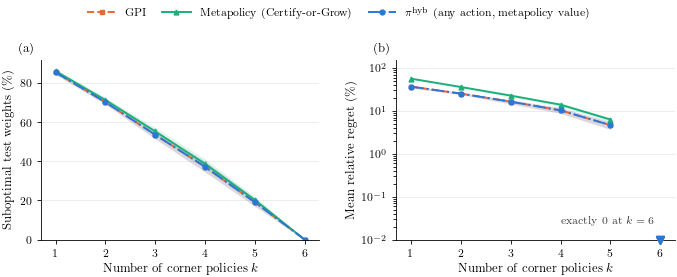

saved ../notes/figures/office_basis_growth.pdf  (TeX rendering: True)


In [8]:
import shutil

os.environ["PATH"] += os.pathsep + "/Library/TeX/texbin"
USE_TEX = shutil.which("latex") is not None
PUB_RC = {
    "text.usetex": USE_TEX, "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "CMU Serif", "DejaVu Serif"], "mathtext.fontset": "cm",
    "font.size": 9, "axes.labelsize": 9, "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
}
STYLE = {"GPI":        dict(color="#eb6834", ls="--", marker="s"),
         "metapolicy": dict(color="#1baf7a", ls="-",  marker="^"),
         "hyb":        dict(color="#2a78d6", ls="-.", marker="o")}
LEGEND = {"GPI": "GPI", "metapolicy": "Metapolicy (Certify-or-Grow)",
          "hyb": r"$\pi^{\mathrm{hyb}}$ (any action, metapolicy value)"}


def plot_growth(M, out_name, x_label):
    ks = np.arange(1, M[("GPI", 0)].shape[1] + 1)
    with plt.rc_context(PUB_RC):
        fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.6))
        for ax, j, ylabel, tag in ((axes[0], 0, r"Suboptimal test weights (\%)", "a"),
                                   (axes[1], 1, r"Mean relative regret (\%)", "b")):
            y_bottom = 1e-2
            for name in POLICIES:
                st = STYLE[name]
                mean, std = M[(name, j)].mean(axis=0), M[(name, j)].std(axis=0)
                if j == 1:                                  # log axis: drop exact zeros
                    keep = mean > 0
                    x, m, lo, hi = ks[keep], mean[keep], np.maximum(mean[keep] - std[keep], mean[keep] * 0.1), mean[keep] + std[keep]
                else:
                    x, m, lo, hi = ks, mean, np.clip(mean - std, 0, None), mean + std
                ax.fill_between(x, lo, hi, color=st["color"], alpha=0.15, lw=0)
                ax.plot(x, m, color=st["color"], ls=st["ls"], lw=1.4, marker=st["marker"], ms=3.5, label=LEGEND[name])
                if j == 1 and (mean == 0).any():           # mark where the curve reaches exactly 0
                    ax.plot(ks[mean == 0][0], y_bottom, marker="v", ms=6, color=st["color"], clip_on=False, zorder=5)
            if j == 1:
                ax.set_yscale("log")
                ax.set_ylim(y_bottom, 150)
                zero_at = [ks[M[(n, 1)].mean(axis=0) == 0][0] for n in POLICIES if (M[(n, 1)].mean(axis=0) == 0).any()]
                if zero_at:
                    ax.annotate(rf"exactly 0 at $k={min(zero_at)}$", xy=(min(zero_at), y_bottom), xytext=(-4, 10),
                                textcoords="offset points", ha="right", va="bottom", fontsize=7.5, color="#333333")
            else:
                ax.set_ylim(bottom=0)
            ax.set_xticks(ks)
            ax.set_xlim(0.7, ks[-1] + 0.3)
            ax.set_xlabel(x_label)
            ax.set_ylabel(ylabel)
            ax.text(-0.02, 1.03, rf"({tag})", transform=ax.transAxes, ha="right", va="bottom", fontsize=9)
            for side in ("top", "right"):
                ax.spines[side].set_visible(False)
            ax.grid(axis="y", color="#e6e6e6", lw=0.5)
            ax.set_axisbelow(True)
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False,
                   handlelength=2.6, columnspacing=1.4)
        fig.tight_layout(w_pad=2.0)
        out = os.path.join("..", "notes", "figures", out_name)
        fig.savefig(out)
        plt.show()
    print(f"saved {out}  (TeX rendering: {USE_TEX})")


plot_growth(M_corner, "office_basis_growth.pdf", r"Number of corner policies $k$")

## Second experiment: Certify-or-Grow from an empty basis, random weights

Instead of the corners, the basis is grown by Certify-or-Grow on a stream of random weights
$w \sim \mathrm{Dirichlet}(\mathbf 1)$: each weight either certifies or adds its exactly solved
policy. Same test set and errors, measured after every growth. Streams stop growing at different
$k$; a finished stream is held at its final error.

final basis size per stream: [6, 7, 8, 6, 8, 6, 6, 6, 7, 6] 

  k           GPI % subopt    metapolicy % subopt           hyb % subopt             GPI rel regret %    metapolicy rel regret %           hyb rel regret %
  1           86.1 +-  4.7           86.9 +-  4.5           86.1 +-  4.7                36.31 +- 1.72              56.15 +- 1.51              36.31 +- 1.72
  2           72.9 +-  5.3           73.8 +-  6.1           70.7 +-  5.6                25.08 +- 2.29              35.39 +- 3.71              24.70 +- 2.83
  3           56.0 +-  6.0           57.4 +-  6.6           51.3 +-  5.7                16.14 +- 2.79              21.11 +- 5.32              14.95 +- 3.96
  4           42.2 +-  8.2           43.4 +- 11.2           37.9 +-  9.5                11.07 +- 3.49              13.78 +- 6.04              10.02 +- 4.49
  5           27.1 +-  9.3           22.2 +-  8.3           18.6 +-  8.3                 6.18 +- 2.75               6.27 +- 3.54               4.64 +- 2.85
  

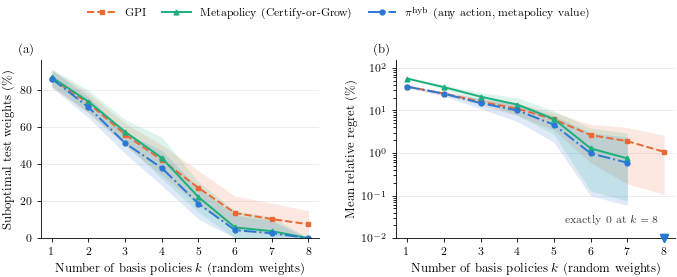

saved ../notes/figures/office_basis_growth_random.pdf  (TeX rendering: True)


In [9]:
def grow(seed, n_train=300):
    rng = np.random.default_rng(seed)
    basis, rows = [], []
    for t in range(n_train):
        w = rng.dirichlet(np.ones(FEAT_DIM))
        if basis:
            _, V, Q, _ = meta_policy_iteration(w, basis)
            if (Q.max(axis=1) - V).max() <= CERT_TOL:
                continue
        basis.append(solve_exact(w))
        rows.append(dict(k=len(basis), **test_errors(basis)))
    return rows


stream_runs = [grow(seed) for seed in range(N_ORDERS)]
K_MAX = max(r[-1]["k"] for r in stream_runs)
print("final basis size per stream:", [r[-1]["k"] for r in stream_runs], "\n")
held = [rows + [dict(rows[-1], k=k) for k in range(rows[-1]["k"] + 1, K_MAX + 1)] for rows in stream_runs]
M_stream = table(held, K_MAX)
plot_growth(M_stream, "office_basis_growth_random.pdf", r"Number of basis policies $k$ (random weights)")

## Reading the result

*(300 held-out weights; corner basis averaged over 10 orderings, random stream over 10 streams.)*

**Corner basis (main figure).**
- With all **6 corner policies, every policy - GPI, metapolicy and $\pi^{\mathrm{hyb}}$ - is
  optimal on every held-out weight**, for every ordering: the corners form a complete basis on
  Office (each one reaches its object by a shortest path from every state, and one episode
  collects a single object).
- The error falls by a roughly constant factor per added corner: GPI / $\pi^{\mathrm{hyb}}$
  relative regret $36.7 \to 25.2 \to 16.4 \to 10.3 \to 4.7 \to 0$%, metapolicy
  $56.3 \to 36.0 \to 22.7 \to 14.0 \to 6.3 \to 0$%.
- For $k < 6$, GPI and $\pi^{\mathrm{hyb}}$ beat the metapolicy (36.7% vs 56.3% at $k = 1$): they
  may take actions that no base policy takes, while the metapolicy is restricted to $B(s)$.
- $\pi^{\mathrm{hyb}}$ and GPI coincide exactly here. With corner policies the metapolicy cannot
  do better than the best single base policy, so $V_{\mathrm{meta}} = \max_j V^{\pi_j}$, and then
  $\pi^{\mathrm{hyb}}$'s one-step backup is exactly GPI's estimate (eq. $(\ast)$ of the notes).

**Random-weight stream (second figure, `office_basis_growth_random.pdf`).**
- Grown by Certify-or-Grow from random weights, the basis needs **6 to 8 policies** to become
  complete (6 on 6 streams, 7 on 2, 8 on 2).
- Here $\pi^{\mathrm{hyb}}$ is the best of the three for $k \ge 2$ (e.g. $k = 6$: 4.3% of weights
  suboptimal vs 5.8% metapolicy and 13.5% GPI), because now the metapolicy's value *is* better
  than the best single base policy and $\pi^{\mathrm{hyb}}$ bootstraps from it. Once the basis is
  complete, the metapolicy and $\pi^{\mathrm{hyb}}$ are exact while GPI is still suboptimal on 7.5%
  of the weights.

**Caveat.** Office is the favourable case - non-conflicting, single-goal objectives. Domains where
the corner policies don't suffice (e.g. DoubleSlit) need their own check.